# 📈 AI Trading Competition
### SDSU AI Club

**Your mission:** build a model that decides when to buy, sell, or sit out of a stock.
We'll test every team's model on real stock prices from a secret time period.

**How this works:**
1. Run the setup cells (Steps 1–3).
2. Try the two example strategies (Step 4).
3. Build your own in the workspace (Step 5). **Anything goes.** Use AI, change the examples, or start from scratch.
4. Submit (Step 6).

| | |
|---|---|
| **Teams** | 2–4 people |
| **Scoring** | 50% how well your model trades (Sharpe ratio, ranked in each round) + 50% how well you explain it |
| **Data rule** | Use only data from **2015 through 2024**, for training, testing, and choosing your model |
| **The test** | 3 secret rounds after 2024, each on a different stock: one lasts a year, one 6 months, one 3 months |
| **Bonus round** | 🚀 SpaceX (SPCX) from its June 2026 IPO. Just for fun, doesn't count toward your score |

🤖 **AI tools are encouraged.** But anyone on your team may be asked how your model works, so make sure you understand what you submit.

---
**Signal Lab prepared workspace.** Run top to bottom. The original organizer setup is preserved unchanged. Numerical candidate ranking uses 2019–2022 folds, and parameter fitting ends in 2022. Feedback from earlier 2023/2024 results motivated additional candidate families, so those years are reused practice/development checks, not untouched tests. Only the organizer's hidden rounds remain unseen final tests. Add your real team members before uploading.


## Step 1 · Team info
Put in your team name and members, then run the cell (▶ button or **Shift+Enter**).

In [ ]:
TEAM_NAME = "Ayaan"  
TEAM_MEMBERS = ["Cameron Penaranda, Justin Paul Liporada"]

# Install only missing libraries, in one call; Colab usually already has them.
import importlib.util
import subprocess
import sys
_requirements = {"numpy": "numpy", "pandas": "pandas", "matplotlib": "matplotlib",
                 "sklearn": "scikit-learn", "cloudpickle": "cloudpickle"}
_missing = [package for module, package in _requirements.items()
            if importlib.util.find_spec(module) is None]
if _missing:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *_missing], check=True)

# Keep the organizer's charts visible in Jupyter and Google Colab.
try:
    get_ipython().run_line_magic("matplotlib", "inline")
except NameError:
    pass


## Step 2 · Setup
Run this cell. It loads the scoring code we'll use on competition day. You don't need to read or edit it.

In [2]:
# @title ⚙️ Setup: run this, no need to open it
import hashlib, inspect, json, subprocess, sys, tempfile, time, types
from datetime import datetime
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

try:
    import cloudpickle
except ImportError:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'cloudpickle'], check=True)
    import cloudpickle

try:
    from IPython.display import display
except ImportError:
    display = print

plt.rcParams.update({'figure.figsize': (11, 4), 'axes.grid': True, 'grid.alpha': 0.25,
                     'axes.spines.top': False, 'axes.spines.right': False,
                     'text.parse_math': False})

WORK_DIR = (Path('/content') if Path('/content').exists() else Path.cwd()) / 'trading_competition'
WORK_DIR.mkdir(parents=True, exist_ok=True)

# The exact scoring engine the organizers use on competition day.
HARNESS_SOURCE = '"""SDSU AI Club trading harness v1.0.\n\nShare this exact file with the organizer-side builder. The member notebook embeds\nthe same bytes. This is a deterministic backtest, not a security sandbox.\n"""\nfrom __future__ import annotations\n\nimport math\nimport time\nfrom typing import Callable\n\nimport numpy as np\nimport pandas as pd\n\nHARNESS_VERSION = \'sdsu-trading-harness-v1.0\'\nOHLCV = [\'Open\', \'High\', \'Low\', \'Close\', \'Volume\']\nFEE_RATE = 0.001\nWARMUP_BARS = 252\nTRADING_DAYS_PER_YEAR = 252\n\n\nclass ContractError(ValueError):\n    """The submitted prediction function broke the published contract."""\n\n\ndef clean_frame(frame: pd.DataFrame) -> pd.DataFrame:\n    """Validate a daily OHLCV frame without filling missing prices."""\n    result = frame.copy()\n    if \'Date\' in result.columns:\n        result = result.set_index(\'Date\')\n    result.index = pd.DatetimeIndex(pd.to_datetime(result.index))\n    if result.index.tz is not None:\n        result.index = result.index.tz_localize(None)\n    result.index = result.index.normalize()\n    result.index.name = \'Date\'\n    if result.index.has_duplicates:\n        raise ValueError(\'Duplicate dates: one stock must have one row per day.\')\n    missing = set(OHLCV) - set(result.columns)\n    if missing:\n        raise ValueError(f\'Missing OHLCV columns: {sorted(missing)}\')\n    result = result[OHLCV].sort_index().astype(float)\n    result.attrs = {}\n    if len(result) == 0 or not np.isfinite(result.to_numpy()).all():\n        raise ValueError(\'Data must contain finite OHLCV values; inspect missing rows.\')\n    if (result[[\'Open\', \'High\', \'Low\', \'Close\']] <= 0).any().any():\n        raise ValueError(\'Prices must be positive.\')\n    if (result[\'Volume\'] < 0).any():\n        raise ValueError(\'Volume cannot be negative.\')\n    if (result[\'High\'] + 1e-6 < result[[\'Open\', \'Close\', \'Low\']].max(axis=1)).any():\n        raise ValueError(\'A High value is below another price in the same bar.\')\n    if (result[\'Low\'] - 1e-6 > result[[\'Open\', \'Close\', \'High\']].min(axis=1)).any():\n        raise ValueError(\'A Low value is above another price in the same bar.\')\n    return result\n\n\ndef checked_position(result) -> float:\n    if isinstance(result, (bool, np.bool_)) or not isinstance(result, (float, np.floating)):\n        raise ContractError(\'predict(history) must return a float, e.g. return float(0.5).\')\n    result = float(result)\n    if not math.isfinite(result) or not -1.0 <= result <= 1.0:\n        raise ContractError(f\'Position {result!r} is not a finite float between -1 and 1.\')\n    return result\n\n\ndef smoke_check_predict(predict: Callable) -> dict:\n    """Check unseen dummy OHLCV input; this data is never used for training."""\n    rng = np.random.default_rng(812)\n    close = 100 * np.exp(np.cumsum(rng.normal(0, .008, WARMUP_BARS)))\n    history = pd.DataFrame({\n        \'Open\': close * .999,\n        \'High\': close * 1.01,\n        \'Low\': close * .99,\n        \'Close\': close,\n        \'Volume\': rng.integers(100_000, 1_000_000, WARMUP_BARS).astype(float),\n    }, index=pd.bdate_range(\'2020-01-02\', periods=WARMUP_BARS, name=\'Date\'))\n    before = history.copy(deep=True)\n    start = time.perf_counter()\n    first = checked_position(predict(history))\n    elapsed = time.perf_counter() - start\n    if not history.equals(before):\n        raise ContractError(\'predict() modified its input. Work on a copy instead.\')\n    second = checked_position(predict(before.copy(deep=True)))\n    if abs(first - second) > 1e-10:\n        raise ContractError(\'Identical histories must produce identical positions.\')\n    flat = before.copy()\n    flat[[\'Open\', \'High\', \'Low\', \'Close\']] = 100.0\n    checked_position(predict(flat))\n    return {\'dummy_position\': first, \'seconds_per_call\': round(elapsed, 4), \'passed\': True}\n\n\ndef _rebalance(cash: float, shares: float, price: float, target: float, fee: float):\n    """Solve for target exposure as a fraction of equity AFTER transaction fees."""\n    equity = cash + shares * price\n    if equity <= 0:\n        raise ContractError(\'A stock allocation became insolvent (equity <= 0).\')\n    gap = target * equity - shares * price\n    denominator = 1.0 + target * fee if gap >= 0 else 1.0 - target * fee\n    notional = gap / denominator\n    cost = fee * abs(notional)\n    cash -= notional + cost\n    shares += notional / price\n    after = cash + shares * price\n    if after <= 0:\n        raise ContractError(\'Transaction fees exhausted a stock allocation.\')\n    if abs(shares * price) > after * (1 + 1e-9):\n        raise ContractError(\'Gross exposure exceeded the no-leverage limit.\')\n    return cash, shares, cost, abs(notional)\n\n\ndef performance_metrics(equity: pd.Series) -> dict:\n    daily = equity.pct_change().dropna()\n    sigma = float(daily.std(ddof=1)) if len(daily) >= 2 else 0.0\n    sharpe = float(np.sqrt(TRADING_DAYS_PER_YEAR) * daily.mean() / sigma) if sigma > 1e-12 else 0.0\n    drawdown = equity / equity.cummax() - 1\n    return {\n        \'Sharpe\': sharpe,\n        \'Total return\': float(equity.iloc[-1] / equity.iloc[0] - 1),\n        \'Max drawdown\': float(drawdown.min()),\n        \'Final equity\': float(equity.iloc[-1]),\n        \'Intervals\': int(len(daily)),\n    }\n\n\ndef run_backtest(data: dict, predict: Callable, start: str, end: str,\n                 initial_capital: float = 10_000.0, fee_rate: float = FEE_RATE,\n                 warmup_bars: int = WARMUP_BARS, budget_seconds: float = 120.0) -> dict:\n    """Observe prior close -> trade next open -> mark at the following open.\n\n    `start` and `end` inclusively select execution/mark dates. The final selected\n    open liquidates all holdings; it is not an additional prediction date.\n    Each stock starts with an equal independent allocation. Allocations are not\n    rebalanced across stocks. No interest, dividends, borrow charges, or slippage\n    beyond the specified fee are separately credited/debited.\n    """\n    if not data or initial_capital <= 0 or not 0 <= fee_rate < .1:\n        raise ValueError(\'Supply stock data, positive capital, and a valid fee rate.\')\n    frames = {str(name): clean_frame(frame) for name, frame in data.items()}\n    dates = None\n    for frame in frames.values():\n        dates = frame.index if dates is None else dates.intersection(frame.index)\n    dates = dates[(dates >= pd.Timestamp(start)) & (dates <= pd.Timestamp(end))].sort_values()\n    if len(dates) < 3:\n        raise ValueError(\'Choose a window containing at least three common trading dates.\')\n    deadline = time.perf_counter() + budget_seconds\n    allocation = initial_capital / len(frames)\n    curves, trades = {}, []\n    total_fees = 0.0\n    for name, frame in frames.items():\n        first = frame.index.get_loc(dates[0])\n        if first < warmup_bars:\n            raise ValueError(f\'{name}: need {warmup_bars} earlier bars before the window starts.\')\n        history_start = first - warmup_bars\n        cash, shares = float(allocation), 0.0\n        values = [allocation]\n        for k, date in enumerate(dates[:-1]):\n            if time.perf_counter() > deadline:\n                raise TimeoutError(\'Local backtest budget exceeded. Simplify predict(); never train inside it.\')\n            at = frame.index.get_loc(date)\n            history = frame.iloc[history_start:at][OHLCV].copy(deep=True)\n            history.attrs = {}\n            position = checked_position(predict(history))\n            if time.perf_counter() > deadline:\n                raise TimeoutError(\'Local backtest budget exceeded during a prediction.\')\n            price = float(frame.at[date, \'Open\'])\n            cash, shares, cost, turnover = _rebalance(cash, shares, price, position, fee_rate)\n            total_fees += cost\n            if turnover > 1e-8:\n                trades.append({\'Stock\': name, \'Execution date\': date,\n                               \'History through\': history.index[-1], \'Target\': position,\n                               \'Notional traded\': turnover, \'Fee\': cost})\n            marked = cash + shares * float(frame.at[dates[k + 1], \'Open\'])\n            if marked <= 0:\n                raise ContractError(f\'{name}: a stock allocation became insolvent. Reduce exposure or shorting.\')\n            values.append(marked)\n        exit_price = float(frame.at[dates[-1], \'Open\'])\n        cash, shares, cost, turnover = _rebalance(cash, shares, exit_price, 0.0, fee_rate)\n        total_fees += cost\n        values[-1] = cash\n        if turnover > 1e-8:\n            trades.append({\'Stock\': name, \'Execution date\': dates[-1],\n                           \'History through\': pd.NaT, \'Target\': 0.0,\n                           \'Notional traded\': turnover, \'Fee\': cost})\n        curves[name] = pd.Series(values, index=dates)\n    by_stock = pd.DataFrame(curves)\n    equity = by_stock.sum(axis=1).rename(\'Portfolio equity\')\n    metrics = performance_metrics(equity)\n    metrics[\'Fees paid\'] = total_fees\n    metrics[\'Trades\'] = len(trades)\n    return {\'equity\': equity, \'daily_returns\': equity.pct_change().dropna(),\n            \'by_stock\': by_stock, \'trades\': pd.DataFrame(trades), \'metrics\': metrics,\n            \'harness_version\': HARNESS_VERSION}\n\n\ndef buy_and_hold(history: pd.DataFrame) -> float:\n    return 1.0\n'
harness = types.ModuleType('sdsu_harness')
exec(compile(HARNESS_SOURCE, 'sdsu_harness.py', 'exec'), harness.__dict__)
HARNESS_SHA = hashlib.sha256(HARNESS_SOURCE.encode()).hexdigest()

FIRST_ALLOWED, LAST_ALLOWED = pd.Timestamp('2015-01-01'), pd.Timestamp('2024-12-31')
PRACTICE_START, PRACTICE_END = '2023-01-01', '2023-12-31'
PRACTICE_STOCKS = ['AAPL', 'JPM', 'XOM', 'JNJ']
DATA = {}
ATTEMPTS = []
ROBUSTNESS_RUNS = []
_latest_training_end = None
STOCK_GROUPS = {
    'Big tech': ['AAPL', 'MSFT', 'NVDA', 'META'],
    'Steady': ['JNJ', 'PG', 'KO', 'DUK'],
    'Struggling': ['INTC', 'F', 'M', 'HOG'],
    'Volatile': ['PLUG', 'AAL', 'CROX', 'BA'],
}
TEST_YEARS_STOCKS = ['JPM', 'XOM', 'PFE', 'CROX', 'M']


def split_by_stock(prices):
    """Turn the long price table into {ticker: daily prices}."""
    prices = prices.copy()
    prices['Date'] = pd.to_datetime(prices['Date'])
    if prices['Date'].min() < FIRST_ALLOWED or prices['Date'].max() > LAST_ALLOWED:
        raise ValueError('This file has dates outside 2015-2024, which is not allowed.')
    return {ticker: harness.clean_frame(group.drop(columns='Ticker'))
            for ticker, group in prices.groupby('Ticker', sort=True)}


def show_stock(ticker, start=None, end=None):
    """Plot a stock's closing price."""
    DATA[ticker]['Close'].loc[start:end].plot(title=f'{ticker} closing price', ylabel='Price ($)')
    plt.show()


def training_data(end='2022-12-31', stocks=None):
    """Get price data up to (and including) `end`. Never later than 2024-12-31."""
    global _latest_training_end
    end = pd.Timestamp(end)
    if end > LAST_ALLOWED:
        raise ValueError('Training data must end on or before 2024-12-31.')
    if _latest_training_end is None or end > _latest_training_end:
        _latest_training_end = end
    stocks = stocks or sorted(DATA)
    return {t: DATA[t].loc[:end].copy() for t in stocks}


def add_stock_csv(path, ticker):
    """Optional: add your own stock. CSV columns: Date, Open, High, Low, Close, Volume."""
    frame = harness.clean_frame(pd.read_csv(path))
    if frame.index.min() < FIRST_ALLOWED or frame.index.max() > LAST_ALLOWED:
        raise ValueError(f'{path}: every row must be between 2015-01-01 and 2024-12-31.')
    DATA[ticker.upper()] = frame
    print(f'Added {ticker.upper()}: {len(frame)} days of data.')


def _source_of(fn):
    try:
        return inspect.getsource(fn)
    except (OSError, TypeError):
        return '(source not available)'


def practice_score(predict, note='', stocks=None, start=PRACTICE_START, end=PRACTICE_END):
    """Test a predict function on the practice period, compared with buy-and-hold."""
    if _latest_training_end is not None and _latest_training_end >= pd.Timestamp(start):
        print(f'⚠️  Heads up: you loaded training data through {_latest_training_end.date()}, which '
              f'overlaps this practice period. If your model trained on it, this score is too optimistic.\n')
    practice = {t: DATA[t] for t in (stocks or PRACTICE_STOCKS)}
    try:
        yours = harness.run_backtest(practice, predict, start, end)
    except (harness.ContractError, TimeoutError) as error:
        print('❌ Your predict function has a problem:', error)
        return None
    hold = harness.run_backtest(practice, harness.buy_and_hold, start, end)
    table = pd.DataFrame({'Your model': yours['metrics'], 'Buy and hold': hold['metrics']}).T
    table = table[['Sharpe', 'Total return', 'Max drawdown', 'Trades', 'Fees paid']]
    shown = table.copy()
    shown['Sharpe'] = table['Sharpe'].map('{:.2f}'.format)
    shown['Total return'] = table['Total return'].map('{:.1%}'.format)
    shown['Max drawdown'] = table['Max drawdown'].map('{:.1%}'.format)
    shown['Trades'] = table['Trades'].map('{:.0f}'.format)
    shown['Fees paid'] = table['Fees paid'].map('${:,.0f}'.format)
    display(shown)
    ax = yours['equity'].plot(label='Your model', linewidth=2)
    hold['equity'].plot(ax=ax, label='Buy and hold', linewidth=1.2, alpha=0.8)
    ax.set(title=f'Practice: {start} to {end} on {", ".join(practice)}', ylabel='Portfolio value ($)')
    ax.legend()
    plt.show()
    ATTEMPTS.append({'Attempt': len(ATTEMPTS) + 1, 'Time': datetime.now().strftime('%H:%M:%S'),
                     'Note': note, 'Sharpe': round(yours['metrics']['Sharpe'], 3),
                     'Return': round(yours['metrics']['Total return'], 4),
                     'Trades': yours['metrics']['Trades'], 'code': _source_of(predict)})
    print(f'Saved as attempt #{len(ATTEMPTS)}. Sharpe: {yours["metrics"]["Sharpe"]:.2f}')
    return yours['metrics']['Sharpe']


def robustness_check(predict, note='', trained_through='auto'):
    """Test across several years and stock groups. Shows whether an edge is consistent or a fluke."""
    if trained_through == 'auto':
        trained_to = _latest_training_end
    else:
        trained_to = pd.Timestamp(trained_through) if trained_through else None
    rows = []
    def run(label, stocks, start, end):
        stocks = [s for s in stocks if s in DATA]
        if not stocks:
            return
        honest = trained_to is None or pd.Timestamp(start) > trained_to
        try:
            yours = harness.run_backtest({s: DATA[s] for s in stocks}, predict, start, end, budget_seconds=300)
        except (harness.ContractError, TimeoutError) as error:
            print('❌ Your predict function has a problem:', error)
            raise
        hold = harness.run_backtest({s: DATA[s] for s in stocks}, harness.buy_and_hold, start, end)
        rows.append({'Test': label, 'Stocks': ', '.join(stocks),
                     'Your Sharpe': yours['metrics']['Sharpe'], 'Buy & hold Sharpe': hold['metrics']['Sharpe'],
                     'Your return': yours['metrics']['Total return'],
                     'Honest?': 'yes' if honest else 'no: model saw this data'})
    print('Testing across years...')
    try:
        for year in range(2020, 2025):
            run(str(year), TEST_YEARS_STOCKS, f'{year}-01-01', f'{year}-12-31')
        group_year = 2024
        if trained_to is not None and trained_to >= pd.Timestamp('2024-01-01'):
            print('(Skipping stock groups: your model trained into 2024, so there is no unseen year left.)')
        else:
            print(f'Testing across stock groups in {group_year}...')
            for name, stocks in STOCK_GROUPS.items():
                run(f'{name} ({group_year})', stocks, f'{group_year}-01-01', f'{group_year}-12-31')
    except (harness.ContractError, TimeoutError):
        return None
    table = pd.DataFrame(rows).set_index('Test')
    shown = table.copy()
    for column in ['Your Sharpe', 'Buy & hold Sharpe']:
        shown[column] = table[column].map('{:.2f}'.format)
    shown['Your return'] = table['Your return'].map('{:.1%}'.format)
    display(shown)
    honest = table[table['Honest?'] == 'yes']
    if honest.empty:
        print('⚠️  Every test overlapped your training data, so none of these scores are honest.')
        print('   Retrain with an earlier end date (for example 2021-12-31) and run this again.')
    else:
        positive = int((honest['Your Sharpe'] > 0).sum())
        beat = int((honest['Your Sharpe'] > honest['Buy & hold Sharpe']).sum())
        print(f'Honest tests: {len(honest)}. Positive Sharpe in {positive}. Beat buy-and-hold in {beat}.')
        print(f'Typical (median) honest Sharpe: {honest["Your Sharpe"].median():.2f}')
        if len(honest) < len(table):
            print('Rows marked "no" overlap your training data. Their scores look better than they really are.')
            print('If your model is a hand-written rule that never trains on data, use:')
            print('   robustness_check(predict, trained_through=None)')
    ROBUSTNESS_RUNS.append({'Time': datetime.now().strftime('%H:%M:%S'), 'Note': note,
                            'results': table.reset_index().to_dict('records'), 'code': _source_of(predict)})
    return table


def _action(previous, target):
    if abs(target - previous) < 1e-9:
        return 'HOLD'
    if target > previous:
        return 'BUY' if target > 0 else 'COVER'
    return 'SELL' if target >= 0 else 'SHORT'


def _simulate_for_watching(predict, stocks, start, end, money):
    """Run the official scoring engine, recording every daily decision."""
    allocation = money / len(stocks)
    per_stock = {}
    for stock in stocks:
        decisions = []
        def recorder(history, _predict=predict, _log=decisions):
            position = _predict(history)
            _log.append(position)
            return position
        result = harness.run_backtest({stock: DATA[stock]}, recorder, start, end, initial_capital=allocation)
        hold = harness.run_backtest({stock: DATA[stock]}, harness.buy_and_hold, start, end, initial_capital=allocation)
        dates = result['equity'].index
        trades = result['trades']
        fees = trades.groupby('Execution date')['Fee'].sum() if len(trades) else pd.Series(dtype=float)
        per_stock[stock] = pd.DataFrame({
            'Price': DATA[stock].loc[dates, 'Open'].to_numpy(),
            'Position': [float(p) for p in decisions] + [0.0],
            'Value': result['equity'].to_numpy(),
            'Hold value': hold['equity'].to_numpy(),
            'Fee': fees.reindex(dates).fillna(0.0).to_numpy(),
        }, index=dates)
        previous, actions = 0.0, []
        for position in per_stock[stock]['Position']:
            actions.append(_action(previous, position))
            previous = position
        actions[-1] = 'CLOSE' if previous != 0 or per_stock[stock]['Position'].iloc[-2] != 0 else 'HOLD'
        per_stock[stock]['Action'] = actions
    return per_stock


def _draw_frame(fig, per_stock, k, money, start, end):
    fig.clf()
    grid = fig.add_gridspec(2, 3, height_ratios=[1, 1.1], width_ratios=[1, 1, 0.9], hspace=0.35, wspace=0.3)
    ax_money = fig.add_subplot(grid[0, :2])
    ax_price = fig.add_subplot(grid[1, :2])
    ax_text = fig.add_subplot(grid[:, 2])
    ax_text.axis('off')
    dates = next(iter(per_stock.values())).index
    shown = dates[:k + 1]
    total = sum(frame['Value'] for frame in per_stock.values())
    hold_total = sum(frame['Hold value'] for frame in per_stock.values())
    fees_so_far = sum(frame['Fee'].iloc[:k + 1].sum() for frame in per_stock.values())

    ax_money.plot(shown, total.iloc[:k + 1], linewidth=2.2, color='#2563eb', label='Your model')
    ax_money.plot(shown, hold_total.iloc[:k + 1], linewidth=1.2, color='#9ca3af', label='Buy and hold')
    ax_money.axhline(money, color='#d1d5db', linewidth=0.8, linestyle='--')
    ax_money.set_xlim(dates[0], dates[-1])
    ax_money.set_ylabel('Account value ($)')
    ax_money.legend(loc='upper left', fontsize=9)
    ax_money.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'${v:,.0f}'))

    palette = ['#2563eb', '#f59e0b', '#7c3aed', '#0891b2', '#db2777', '#78716c', '#65a30d', '#1e3a8a']
    for i, (stock, frame) in enumerate(per_stock.items()):
        change = frame['Price'] / frame['Price'].iloc[0] * 100 - 100
        ax_price.plot(shown, change.iloc[:k + 1], linewidth=1.3, label=stock, color=palette[i % len(palette)])
        recent = frame.iloc[:k + 1]
        buys = recent['Action'].isin(['BUY', 'COVER'])
        sells = recent['Action'].isin(['SELL', 'SHORT', 'CLOSE'])
        ax_price.scatter(recent.index[buys], change.iloc[:k + 1][buys], marker='^', s=28,
                         color='#16a34a', zorder=3, edgecolors='white', linewidths=0.4)
        ax_price.scatter(recent.index[sells], change.iloc[:k + 1][sells], marker='v', s=28,
                         color='#dc2626', zorder=3, edgecolors='white', linewidths=0.4)
    ax_price.set_xlim(dates[0], dates[-1])
    for axis in (ax_money, ax_price):
        axis.xaxis.set_major_locator(mdates.MonthLocator())
        axis.xaxis.set_major_formatter(mdates.DateFormatter('%b'))
    ax_price.set_ylabel('Stock price change (%)')
    ax_price.legend(loc='upper left', fontsize=8, ncol=min(4, len(per_stock)))
    ax_price.set_title('Green = buy, red = sell/short', fontsize=9, loc='right', color='#6b7280')

    now = dates[k]
    value = total.iloc[k]
    profit = value - money
    fig.suptitle(f'Day {k + 1} of {len(dates)}  |  {now:%a %b %d, %Y}  |  Account ${value:,.0f}  '
                 f'({profit:+,.0f}, {profit / money:+.1%})  |  Fees so far ${fees_so_far:,.0f}',
                 fontsize=12, fontweight='bold', x=0.02, ha='left')

    invested_total = sum(abs(frame['Position'].iloc[k]) * frame['Value'].iloc[k] for frame in per_stock.values())
    lines = ['MONEY RIGHT NOW', '',
             f'Invested  ${invested_total:,.0f}',
             f'Cash      ${max(value - invested_total, 0):,.0f}',
             f'Total     ${value:,.0f}', '',
             'EACH STOCK TODAY', '']
    for stock, frame in per_stock.items():
        row = frame.iloc[k]
        size = abs(row['Position'])
        state = 'all cash' if size == 0 else f"{size:.0%} {'long' if row['Position'] > 0 else 'short'}"
        gain = row['Value'] - money / len(per_stock)
        lines.append(f"{stock:<6}{row['Action']:<6}-> {state}")
        lines.append(f"      ${row['Value']:,.0f} ({'+' if gain >= 0 else '-'}${abs(gain):,.0f})")
    lines += ['', 'RECENT TRADES', '']
    log = []
    for stock, frame in per_stock.items():
        recent = frame.iloc[:k + 1]
        for date, row in recent[recent['Action'] != 'HOLD'].iterrows():
            log.append((date, f"{date:%b %d} {stock:<5}{row['Action']:<6}@ ${row['Price']:,.2f}"))
    for _, text in sorted(log)[-8:][::-1]:
        lines.append(text)
    if not log:
        lines.append('(no trades yet)')
    ax_text.text(0, 1, '\n'.join(lines), va='top', ha='left', family='monospace', fontsize=9.5,
                 transform=ax_text.transAxes)


def watch_trading(predict, stocks=None, start=PRACTICE_START, end=PRACTICE_END, money=10_000, speed='normal'):
    """Watch your model trade day by day, then see the final results.

    speed: 'slow', 'normal', 'fast', or 'instant' (skip straight to the results).
    """
    stocks = stocks or PRACTICE_STOCKS
    if _latest_training_end is not None and _latest_training_end >= pd.Timestamp(start):
        print(f'⚠️  Your training data goes through {_latest_training_end.date()}, which overlaps this period. '
              f'Results will look better than they really are.\n')
    print('Running the simulation...')
    try:
        per_stock = _simulate_for_watching(predict, stocks, start, end, money)
    except (harness.ContractError, TimeoutError) as error:
        print('❌ Your predict function has a problem:', error)
        return None
    days = len(next(iter(per_stock.values())))
    step = {'slow': 1, 'normal': 2, 'fast': 5}.get(speed)
    fig = plt.figure(figsize=(14, 7.5))
    try:
        from IPython.display import display as _show
        handle = _show(fig, display_id=True) if step else None
    except ImportError:
        handle = None
    plt.close(fig)
    if handle is not None:
        for k in list(range(0, days, step)) + [days - 1]:
            _draw_frame(fig, per_stock, k, money, start, end)
            handle.update(fig)
    else:
        _draw_frame(fig, per_stock, days - 1, money, start, end)
        try:
            _show(fig)
        except NameError:
            pass

    total = sum(frame['Value'] for frame in per_stock.values())
    hold_total = sum(frame['Hold value'] for frame in per_stock.values())
    yours = harness.performance_metrics(total)
    hold = harness.performance_metrics(hold_total)
    rows = []
    for stock, frame in per_stock.items():
        start_money = money / len(per_stock)
        rows.append({'Stock': stock, 'Started with': start_money, 'Ended with': frame['Value'].iloc[-1],
                     'Profit': frame['Value'].iloc[-1] - start_money,
                     'Trades': int((frame['Action'] != 'HOLD').sum()), 'Fees': frame['Fee'].sum(),
                     'Buy & hold profit': frame['Hold value'].iloc[-1] - start_money})
    table = pd.DataFrame(rows).set_index('Stock')
    table.loc['TOTAL'] = table.sum()
    table['Trades'] = table['Trades'].astype(int)
    for column in ['Started with', 'Ended with', 'Profit', 'Fees', 'Buy & hold profit']:
        table[column] = table[column].map(lambda v: f'${v:,.0f}' if v >= 0 else f'-${-v:,.0f}')
    print('\n📊 FINAL RESULTS')
    display(table)
    profit = total.iloc[-1] - money
    print(f'Net profit: ${profit:,.2f} ({profit / money:+.1%})   |   Buy and hold: '
          f'${hold_total.iloc[-1] - money:,.2f} ({hold["Total return"]:+.1%})')
    print(f'Sharpe (competition score): {yours["Sharpe"]:.2f}   |   Buy and hold: {hold["Sharpe"]:.2f}')
    print(f'Worst drop from a peak: {yours["Max drawdown"]:.1%}')
    return per_stock


def show_attempts():
    """Table of every practice run so far."""
    if not ATTEMPTS:
        print('No attempts yet. Run practice_score(...) first.')
        return
    display(pd.DataFrame(ATTEMPTS).drop(columns='code').set_index('Attempt'))


_CHECK_IN_FRESH_PYTHON = r"""
import sys, cloudpickle, numpy as np, pandas as pd
bundle = cloudpickle.load(open(sys.argv[1], 'rb'))
rng = np.random.default_rng(7)
close = 100 * np.exp(np.cumsum(rng.normal(0, 0.01, 300)))
history = pd.DataFrame({'Open': close * 0.999, 'High': close * 1.01, 'Low': close * 0.99,
                        'Close': close, 'Volume': np.full(300, 1e6)},
                       index=pd.bdate_range('2021-01-04', periods=300, name='Date'))
position = bundle['predict'](history)
assert isinstance(position, (float, np.floating)) and -1 <= position <= 1, position
print('ok')
"""


def save_submission(predict):
    """Check your predict function, then save it into one file for upload."""
    if not ATTEMPTS:
        print('⚠️  You have no practice attempts yet. Run practice_score(predict) at least once first.\n')
    try:
        check = harness.smoke_check_predict(predict)
    except Exception as error:
        print('❌ Not saved. Your predict function failed a basic check:', error)
        return
    short = harness.clean_frame(pd.DataFrame(
        {'Open': 100.0, 'High': 101.0, 'Low': 99.0, 'Close': 100.0, 'Volume': 1e6},
        index=pd.bdate_range('2026-06-12', periods=5, name='Date')))
    try:
        harness.checked_position(predict(short))
        bonus_ready = True
    except Exception as error:
        bonus_ready = False
        print('⚠️  Heads up: your model crashes with only a few days of history:', error)
        print('   It will sit out the SpaceX bonus round. Fix: return 0.0 when there is not enough data.\n')
    try:
        ip = get_ipython()  # noqa: F821 (exists inside Colab/Jupyter)
        cell_history = [cell for cell in ip.user_ns.get('In', []) if cell.strip()]
    except NameError:
        cell_history = []
    bundle = {
        'predict': predict,
        'team_name': TEAM_NAME,
        'team_members': TEAM_MEMBERS,
        'saved_at': datetime.now().isoformat(timespec='seconds'),
        'latest_training_data_end': str(_latest_training_end.date()) if _latest_training_end is not None else None,
        'practice_attempts': ATTEMPTS,
        'robustness_checks': ROBUSTNESS_RUNS,
        'cell_history': cell_history,
        'predict_source': _source_of(predict),
        'harness_sha256': HARNESS_SHA,
        'handles_short_history': bonus_ready,
        'python_version': sys.version.split()[0],
    }
    try:
        payload = cloudpickle.dumps(bundle)
    except Exception as error:
        print('❌ Not saved. Your model could not be packaged:', error)
        print('   Ask an organizer. Usually this means predict() uses something that cannot be saved, like an open file.')
        return
    if len(payload) > 100_000_000:
        print(f'❌ Not saved. Your submission is {len(payload) / 1e6:.0f} MB; the limit is 100 MB. Try a smaller model.')
        return
    slug = ''.join(c if c.isalnum() else '_' for c in TEAM_NAME).strip('_') or 'team'
    path = WORK_DIR / f'{slug}_submission.pkl'
    path.write_bytes(payload)
    result = subprocess.run([sys.executable, '-c', _CHECK_IN_FRESH_PYTHON, str(path)],
                            capture_output=True, text=True, timeout=120)
    if result.returncode != 0:
        print('❌ Saved, but the file does not work outside this notebook. Show this to an organizer:')
        print(result.stderr[-1500:])
        return
    print(f'✅ {path.name} saved and checked ({len(payload) / 1e6:.1f} MB).')
    print(f'   Test position on sample data: {check["dummy_position"]}')
    try:
        from google.colab import files
        files.download(str(path))
    except ImportError:
        print('   File location:', path)
    return path


print('✅ Setup done.')

✅ Setup done.


## Step 3 · Load the data
**Where it comes from:** daily prices for 12 well-known stocks from Yahoo Finance, January 2015 through
December 2024. Organizers downloaded it ahead of time and posted it as one file, so the whole room isn't
hitting Yahoo at once. You can open the link in your browser to see the raw file.

Each row is one stock on one day:
- **Open:** price when the market opened
- **High / Low:** highest and lowest price that day
- **Close:** price when the market closed
- **Volume:** how many shares were traded

In [3]:
DATA_URL = "https://raw.githubusercontent.com/aiclub-sdsu/workshops/refs/heads/main/Fall26/AI_Trading_Competition/stock_prices_2015_2024.csv"

if DATA_URL.startswith("PASTE"):
    raise ValueError("The data link hasn't been filled in yet. Ask an organizer.")
# Prefer the supplied local CSV; otherwise use the original organizer URL.
_csv_name = "stock_prices_2015_2024.csv"
_local_options = [Path.cwd() / "data" / _csv_name, Path.cwd() / _csv_name,
                  WORK_DIR / "data" / _csv_name,
                  Path.cwd() / "outputs" / "competition-submission" / "data" / _csv_name]
_local_csv = next((path for path in _local_options if path.is_file()), None)
prices = pd.read_csv(_local_csv if _local_csv is not None else DATA_URL)
print("Data source:", _local_csv if _local_csv is not None else DATA_URL)
DATA = split_by_stock(prices)

print(f"Loaded {len(DATA)} stocks:", ", ".join(DATA))
prices.head()

Data source: /Users/camskimac/Documents/Codex/2026-10-30/meeting-10-30-ai-stock-trading/outputs/competition-submission/data/stock_prices_2015_2024.csv


Loaded 34 stocks: AAL, AAPL, AMZN, BA, C, CAT, CROX, CVX, DIS, DUK, F, GIS, GOOGL, HOG, HON, INTC, JNJ, JPM, KO, M, META, MMM, MSFT, NEE, NKE, NVDA, PFE, PG, PLUG, T, UNH, VZ, WMT, XOM


,Date,Ticker,Open,High,Low,Close,Volume
0,2015-01-02,AAL,51.430489,51.733690,50.284011,51.079914,10748600
1,2015-01-02,AAPL,24.627205,24.638260,23.734002,24.171761,212818400
2,2015-01-02,AMZN,15.629000,15.737500,15.348000,15.426000,55664000
3,2015-01-02,BA,114.636798,115.310248,112.905035,113.657211,4294200
4,2015-01-02,C,39.884954,40.127080,39.466735,39.811581,11137800


## Step 4 · The submitted model

`predict(history)` receives a pandas DataFrame of one unnamed stock's daily
Open/High/Low/Close/Volume through the previous close. It returns a Python float
from −1 (short) to 1 (long). The organizer harness executes at the next open and
marks the position at the following open, with transaction fees.

The next cell embeds the complete strategy source so this notebook and its
saved predictor do not depend on a separate local `strategy.py`. It defines
features and model classes; it does not fit inside `predict()`.


### The actual selected decision, in plain English

The final saved model uses the organizer's **20-day / 100-day trend rule**. On valid input, it compares those two averages of Close: it returns `1.0` when the 20-day average is higher, and `0.0` otherwise. It returns cash with fewer than 100 bars. It never shorts. The fitted Ridge and tree models remain in the notebook as experiments; they were not selected.

This is a fixed rule with **no learned coefficients**. The historical validation chose it from five alternatives. Explain that distinction to the judges. Its 2023 practice Sharpe was about **0.14**, versus **1.19** for buying and holding, so these results do not show a competitive advantage over that benchmark.


In [4]:
# Define the complete strategy; no training happens in this cell.
"""Small causal models for the published SDSU trading harness.

Training learns from next-open to following-open returns. Prediction reads only
the supplied history, identifies no ticker, and never fits or changes state.
"""
# Definitions are embedded directly in this notebook.

from dataclasses import asdict, dataclass
from typing import Mapping

import numpy as np
import pandas as pd


OHLCV = ("Open", "High", "Low", "Close", "Volume")
FEATURE_NAMES = (
    "return_1", "return_5", "return_20", "return_60", "return_120",
    "trend_20", "trend_100", "volatility_20", "volatility_60",
    "daily_range", "relative_volume_20", "opening_gap", "intraday_return",
    "close_location",
)
MIN_HISTORY = 121


@dataclass(frozen=True)
class StrategyConfig:
    """Fixed choices; select them using chronological training-period folds."""
    target_vol: float = 0.12
    max_long: float = 0.80
    max_short: float = 0.25
    ml_weight: float = 0.30
    ml_strength: float = 3.0
    trend_bias: float = 0.30
    trend_strength: float = 0.90
    exposure_step: float = 0.05
    deadband: float = 0.05
    ridge_alpha: float = 100.0
    n_estimators: int = 40
    max_depth: int = 4
    min_samples_leaf: int = 80
    random_state: int = 42


def _config(value=None):
    if isinstance(value, StrategyConfig):
        result = value
    else:
        supplied = dict(value or {})
        unknown = set(supplied) - set(StrategyConfig.__dataclass_fields__)
        if unknown:
            raise ValueError(f"Unknown strategy config: {sorted(unknown)}")
        result = StrategyConfig(**supplied)
    for name, number in asdict(result).items():
        if not isinstance(number, (float, int)) or not np.isfinite(number):
            raise ValueError(f"{name} must be finite")
    if not (0 < result.target_vol <= 1 and 0 <= result.max_long <= 1 and 0 <= result.max_short <= 1):
        raise ValueError("Volatility target must be positive; long/short caps must be in [0, 1]")
    if not (0 <= result.ml_weight <= 1 and result.ml_strength >= 0):
        raise ValueError("ML weight must be in [0, 1] and its strength nonnegative")
    if not (0 <= result.exposure_step <= .5 and 0 <= result.deadband < 1):
        raise ValueError("Invalid exposure step or deadband")
    if result.ridge_alpha <= 0:
        raise ValueError("Ridge regularization must be positive")
    for name in ("n_estimators", "max_depth", "min_samples_leaf", "random_state"):
        if not isinstance(getattr(result, name), int):
            raise ValueError(f"{name} must be an integer")
    if not (1 <= result.n_estimators <= 100 and 1 <= result.max_depth <= 8 and result.min_samples_leaf >= 10):
        raise ValueError("Use a small forest with positive depth and at least 10 rows per leaf")
    return result


def _rolling(values, window, statistic="mean"):
    """Each result uses its own exact window, independent of earlier rows."""
    out = np.full(len(values), np.nan)
    if len(values) >= window:
        windows = np.lib.stride_tricks.sliding_window_view(values, window)
        out[window - 1:] = windows.std(axis=1, ddof=1) if statistic == "std" else windows.mean(axis=1)
    return out


def make_features(frame):
    """Causal batch features for fitting; the final row matches tail(252).

    No price levels, ticker identifiers, dates, or future values are features.
    The maximum lag is 120; no expanding statistics or recursive averages occur.
    """
    close = frame["Close"].to_numpy(dtype=float)
    opening = frame["Open"].to_numpy(dtype=float)
    high = frame["High"].to_numpy(dtype=float)
    low = frame["Low"].to_numpy(dtype=float)
    volume = frame["Volume"].to_numpy(dtype=float)
    n = len(frame)
    columns = []
    for lag in (1, 5, 20, 60, 120):
        values = np.full(n, np.nan)
        if n > lag:
            values[lag:] = close[lag:] / close[:-lag] - 1
        columns.append(values)
    r1 = columns[0]
    with np.errstate(divide="ignore", invalid="ignore"):
        columns.extend((close / _rolling(close, 20) - 1,
                        close / _rolling(close, 100) - 1,
                        _rolling(r1, 20, "std"), _rolling(r1, 60, "std"),
                        (high - low) / close))
        average_volume = _rolling(volume, 20)
        relative_volume = np.divide(volume, average_volume, out=np.ones(n), where=average_volume > 0) - 1
        gap = np.full(n, np.nan)
        if n > 1:
            gap[1:] = opening[1:] / close[:-1] - 1
        location = np.divide(close - low, high - low, out=np.full(n, .5), where=high > low)
        columns.extend((relative_volume, gap, close / opening - 1, location))
    return pd.DataFrame(np.column_stack(columns), index=frame.index, columns=FEATURE_NAMES)


def _latest_features(history):
    """Fast last-row equivalent of make_features; at most 121 rows are read."""
    values = history.iloc[-MIN_HISTORY:].loc[:, list(OHLCV)].to_numpy(dtype=float)
    if values.shape[0] < MIN_HISTORY or not np.isfinite(values).all():
        return None
    opening, high, low, close, volume = values.T
    if np.any(values[:, :4] <= 0) or np.any(volume < 0):
        return None
    returns = close[1:] / close[:-1] - 1
    volume_mean = volume[-20:].mean()
    width = high[-1] - low[-1]
    x = np.array([
        *[close[-1] / close[-1 - lag] - 1 for lag in (1, 5, 20, 60, 120)],
        close[-1] / close[-20:].mean() - 1,
        close[-1] / close[-100:].mean() - 1,
        returns[-20:].std(ddof=1), returns[-60:].std(ddof=1),
        width / close[-1], volume[-1] / volume_mean - 1 if volume_mean > 0 else 0,
        opening[-1] / close[-2] - 1, close[-1] / opening[-1] - 1,
        (close[-1] - low[-1]) / width if width > 0 else .5,
    ])
    return x if np.isfinite(x).all() else None


def _readonly(value):
    result = np.array(value, dtype=float, copy=True)
    result.flags.writeable = False
    return result


@dataclass(frozen=True)
class FrozenStrategy:
    kind: str
    config: StrategyConfig
    means: np.ndarray
    scales: np.ndarray
    coefficients: np.ndarray
    intercept: float
    trees: tuple
    training_rows: int
    training_start: str | None
    training_end: str | None
    training_label_end: str | None
    stocks_used: int

    def predict(self, history):
        """Return a deterministic Python float exposure using prior data only."""
        if self.kind in ("starter_trend", "defensive_trend"):
            if len(history) < 100:
                return 0.0
            close = history["Close"].iloc[-100:].to_numpy(dtype=float)
            if not np.isfinite(close).all() or np.any(close <= 0):
                return 0.0
            fast, slow = float(close[-20:].mean()), float(close.mean())
            bullish = fast > slow
            if self.kind == "starter_trend":
                # Exactly the provided starter rule: full long above, cash below.
                return 1.0 if bullish else 0.0
            if not bullish or close[-1] <= slow:
                return 0.0
            daily = close[-20:] / close[-21:-1] - 1
            annual_vol = float(daily.std(ddof=1) * np.sqrt(252))
            tier = .75 if annual_vol < .35 else .50
            # Fixed quarter-size tiers avoid small daily risk-target adjustments.
            return float(np.floor(min(tier, self.config.max_long) / .25) * .25)
        if len(history) < MIN_HISTORY:
            return 0.0
        x = _latest_features(history)
        if x is None:
            return 0.0
        config = self.config
        sigma20, sigma60 = max(x[7], .003), max(x[8], .003)
        # Slow trend changes less often than a daily up/down prediction.
        trend_z = (.50 * x[6] / (sigma60 * np.sqrt(100))
                   + .35 * x[3] / (sigma60 * np.sqrt(60))
                   + .15 * x[5] / (sigma20 * np.sqrt(20)))
        trend = float(np.clip(config.trend_bias + config.trend_strength * np.tanh(1.2 * trend_z), -1, 1))
        score = trend
        if self.kind != "trend":
            z = np.clip((x - self.means) / self.scales, -8, 8)
            if self.kind == "ridge":
                predicted = float(self.intercept + z @ self.coefficients)
            else:
                predictions = []
                for feature, threshold, left, right, leaf_value in self.trees:
                    node = 0
                    while left[node] >= 0:
                        node = left[node] if z[feature[node]] <= threshold[node] else right[node]
                    predictions.append(leaf_value[node])
                predicted = float(np.mean(predictions))
            ml_score = float(np.tanh(config.ml_strength * predicted))
            score = (1 - config.ml_weight) * trend + config.ml_weight * ml_score
        annual_vol = max(sigma20 * np.sqrt(252), .06)
        risk_scale = min(1.0, config.target_vol / annual_vol)
        position = float(np.clip(score * risk_scale, -config.max_short, config.max_long))
        if abs(position) < config.deadband:
            return 0.0
        if config.exposure_step:
            position = float(np.round(position / config.exposure_step) * config.exposure_step)
        return float(np.clip(position, -config.max_short, config.max_long))

    def describe(self):
        rule = self.kind in ("trend", "starter_trend", "defensive_trend")
        simple_rule = self.kind in ("starter_trend", "defensive_trend")
        return {
            "kind": self.kind,
            "features": list(FEATURE_NAMES),
            "target": "No fitted prediction target; fixed trading rule" if rule else "Open[t+2] / Open[t+1] - 1, divided by trailing 20-day close-return volatility",
            "timing": "history through close t; position executed at open t+1; marked at open t+2",
            "minimum_history": 100 if simple_rule else MIN_HISTORY,
            "learned_parameters": not rule,
            "training_rows": self.training_rows,
            "training_start": self.training_start,
            "training_end": self.training_end,
            "training_label_end": self.training_label_end,
            "stocks_used": self.stocks_used,
            "config": asdict(self.config),
            "standardized_coefficients": dict(zip(FEATURE_NAMES, self.coefficients.tolist())) if self.kind == "ridge" else {},
            "explanation": ("Exact starter rule: 20-day average above 100-day average means 100% long; otherwise cash. No fitted parameters."
                            if self.kind == "starter_trend" else
                            "Fixed defensive rule: 20-day average and latest close above the 100-day average; 75% long below 35% annual volatility, 50% otherwise, subject to the configured cap and quarter-size tiers; cash when the trend fails. No fitted parameters."
                            if self.kind == "defensive_trend" else
                            "Fixed smooth trend with volatility sizing and exposure bins; no fitted parameters."
                            if self.kind == "trend" else
                            "Slow price trend blended with a small fitted return model, trailing-volatility sizing, asymmetric long/short caps, and exposure bins. No state or fitting in predict."),
        }


def fit_strategy(training_frames, kind="ridge", config=None):
    """Fit using ONLY the caller-supplied training slice; never fetch data.

    Each stock is processed independently. Both future opens of every training
    target must exist inside that stock's supplied slice. Normalization means
    and scales are learned from these eligible training examples only.
    """
    config = _config(config)
    if kind == "extra":
        kind = "extra_trees"
    rule = kind in ("trend", "starter_trend", "defensive_trend")
    if kind not in ("trend", "ridge", "extra_trees", "starter_trend", "defensive_trend"):
        raise ValueError("kind must be trend, starter_trend, defensive_trend, ridge, or extra_trees")
    frames = list(training_frames.values()) if isinstance(training_frames, Mapping) else list(training_frames)
    xs, ys, starts, ends, label_ends = [], [], [], [], []
    for frame in frames:
        if len(frame) < MIN_HISTORY + 2:
            continue
        if not frame.index.is_monotonic_increasing or frame.index.has_duplicates:
            raise ValueError("Training histories must have ascending unique dates")
        raw = frame.loc[:, list(OHLCV)].to_numpy(dtype=float)
        if not np.isfinite(raw).all() or np.any(raw[:, :4] <= 0) or np.any(raw[:, 4] < 0):
            raise ValueError("Training OHLCV values must be finite with positive prices and nonnegative volume")
        features = make_features(frame)
        opening = frame["Open"].to_numpy(dtype=float)
        target = np.full(len(frame), np.nan)
        target[:-2] = opening[2:] / opening[1:-1] - 1
        values = features.to_numpy()
        usable = np.isfinite(values).all(axis=1) & np.isfinite(target)
        indices = np.flatnonzero(usable)
        if not len(indices):
            continue
        xs.append(values[usable])
        # Vol normalization pools unnamed stocks without rewarding high-vol ones.
        ys.append(np.clip(target[usable] / np.maximum(values[usable, 7], .003), -5, 5))
        starts.append(str(frame.index[indices[0]].date()))
        ends.append(str(frame.index[indices[-1]].date()))
        label_ends.append(str(frame.index[indices[-1] + 2].date()))
    if not xs:
        if not rule:
            raise ValueError("Need at least 123 bars per training stock for causal features and labels")
        x = np.empty((0, len(FEATURE_NAMES)))
        y = np.empty(0)
    else:
        x, y = np.concatenate(xs), np.concatenate(ys)
    if not rule and len(x) < 120:
        raise ValueError("Need at least 120 eligible training examples")
    means = x.mean(axis=0) if len(x) else np.zeros(len(FEATURE_NAMES))
    scales = x.std(axis=0) if len(x) else np.ones(len(FEATURE_NAMES))
    scales = np.where(scales > 1e-12, scales, 1.0)
    z = np.clip((x - means) / scales, -8, 8)
    coefficients = np.zeros(len(FEATURE_NAMES))
    intercept = 0.0
    trees = []
    if kind == "ridge":
        intercept = float(y.mean())
        centered = z - z.mean(axis=0)
        coefficients = np.linalg.solve(centered.T @ centered + config.ridge_alpha * np.eye(z.shape[1]), centered.T @ (y - intercept))
        # Clipping standardized inputs means their mean need not be exactly zero.
        intercept = float(y.mean() - z.mean(axis=0) @ coefficients)
    elif kind == "extra_trees":
        from sklearn.ensemble import ExtraTreesRegressor
        model = ExtraTreesRegressor(n_estimators=config.n_estimators, max_depth=config.max_depth,
                                    min_samples_leaf=config.min_samples_leaf, max_features=.75,
                                    random_state=config.random_state, n_jobs=1)
        model.fit(z, y)
        for estimator in model.estimators_:
            t = estimator.tree_
            arrays = (t.feature.copy(), t.threshold.copy(), t.children_left.copy(), t.children_right.copy(), t.value[:, 0, 0].copy())
            for a in arrays:
                a.flags.writeable = False
            trees.append(arrays)
    return FrozenStrategy(kind, config, _readonly(means), _readonly(scales), _readonly(coefficients),
                          intercept, tuple(trees), len(x), min(starts) if starts else None,
                          max(ends) if ends else None, max(label_ends) if label_ends else None, len(xs))


## Step 5 · Reproducible selection and evaluation

The next cell embeds the full workflow. It defines the candidate comparison,
date boundaries, and exact organizer-harness evaluation. The following cell
runs that workflow once, then keeps its selected model frozen. A weak first
attempt is preserved in `initial_attempt.json`. Its 2023/2024 results motivated
adding candidate families: those years are reused development checks. Candidate
numerical ranking still uses 2019–2022 folds, and fitting ends in 2022. The
organizer's hidden rounds are the unseen final tests.


In [5]:
# Define the workflow; its local strategy definitions are already above.
"""Reproducible model selection using the organizer's exact trading harness."""
# Definitions are embedded directly in this notebook.

import json
import platform
from pathlib import Path

import numpy as np
import pandas as pd
# Definitions are embedded directly in this notebook.

# These choices are set before seeing the 2023 practice or 2024 results.
VALIDATION_YEARS = (2019, 2020, 2021, 2022)
VALIDATION_STOCKS = ("AAPL", "JPM", "XOM", "JNJ", "CROX", "INTC", "PLUG", "KO")
PRACTICE_STOCKS_FIXED = ("AAPL", "JPM", "XOM", "JNJ")
CANDIDATES = ("trend", "ridge", "extra_trees", "starter_trend", "defensive_trend")


def _json_ready(value):
    if isinstance(value, dict):
        return {str(key): _json_ready(item) for key, item in value.items()}
    if isinstance(value, (list, tuple)):
        return [_json_ready(item) for item in value]
    if isinstance(value, np.generic):
        return value.item()
    if isinstance(value, (pd.Timestamp, Path)):
        return str(value)
    return value


def run_workflow(DATA, output_dir):
    """Train on allowed past data, select before 2023, then evaluate once.

    The final fitted object remains trained only through December 2022.
    Practice-year rows are supplied to the scoring harness as historical inputs,
    but their labels never enter fit_strategy or the numerical selection score.
    Initial 2023/2024 diagnostics motivated a lower-turnover candidate family;
    those years are reused development checks, not an untouched final test.
    """
    output_dir = Path(output_dir)
    output_dir.mkdir(parents=True, exist_ok=True)
    frames = {str(ticker): harness.clean_frame(frame) for ticker, frame in DATA.items()}
    for frame in frames.values():
        if frame.index.min() < pd.Timestamp("2015-01-01") or frame.index.max() > pd.Timestamp("2024-12-31"):
            raise ValueError("Only the organizer's 2015–2024 data is allowed.")
    validation_names = [ticker for ticker in VALIDATION_STOCKS if ticker in frames]
    practice_names = [ticker for ticker in PRACTICE_STOCKS_FIXED if ticker in frames]
    if not validation_names or not practice_names:
        raise ValueError("Load the official club dataset before training.")
    validation_data = {ticker: frames[ticker] for ticker in validation_names}
    records = []
    for year in VALIDATION_YEARS:
        end = f"{year - 1}-12-31"
        training = {ticker: frame.loc["2015-01-01":end].copy() for ticker, frame in frames.items()}
        for kind in CANDIDATES:
            fitted = fit_strategy(training, kind=kind)
            assert fitted.training_label_end < f"{year}-01-01"
            result = harness.run_backtest(validation_data, fitted.predict,
                                          f"{year}-01-01", f"{year}-12-31", budget_seconds=300)
            records.append({"kind": kind, "year": year, "fit_through": end,
                            "last_training_label": fitted.training_label_end,
                            **result["metrics"]})
            print(f"Validation {year} / {kind}: Sharpe {result['metrics']['Sharpe']:.3f}", flush=True)
    validation_table = pd.DataFrame(records)
    summary = validation_table.groupby("kind", sort=True)["Sharpe"].agg(
        mean_sharpe="mean", std_sharpe="std").reset_index()
    # Reward a good average and penalize unstable results across different years.
    summary["selection_score"] = summary["mean_sharpe"] - .25 * summary["std_sharpe"]
    summary = summary.sort_values(["selection_score", "kind"], ascending=[False, True]).reset_index(drop=True)
    selected_kind = str(summary.iloc[0]["kind"])
    final_training = {ticker: frame.loc["2015-01-01":"2022-12-31"].copy()
                      for ticker, frame in frames.items()}
    model = fit_strategy(final_training, kind=selected_kind)
    assert model.training_label_end <= "2022-12-31"
    smoke = harness.smoke_check_predict(model.predict)
    practice_data = {ticker: frames[ticker] for ticker in practice_names}
    practice_result = harness.run_backtest(practice_data, model.predict,
                                           "2023-01-01", "2023-12-31", budget_seconds=300)
    hold_result = harness.run_backtest(practice_data, harness.buy_and_hold,
                                       "2023-01-01", "2023-12-31", budget_seconds=300)
    practice_table = pd.DataFrame({"Selected model": practice_result["metrics"],
                                   "Buy and hold": hold_result["metrics"]}).T
    practice_result["equity"].to_csv(output_dir / "practice_equity.csv")
    practice_result["trades"].to_csv(output_dir / "practice_trades.csv", index=False)
    validation_table.to_csv(output_dir / "validation_results.csv", index=False)
    summary.to_csv(output_dir / "model_selection.csv", index=False)
    practice_table.to_csv(output_dir / "practice_metrics.csv")
    report = {
        "selected_kind": selected_kind,
        "selection_rule": "Highest mean validation Sharpe minus 0.25 times its across-year standard deviation; ties alphabetically. Set before 2023 testing.",
        "training": {"stocks": sorted(final_training), "date_start": "2015-01-01",
                     "date_end": "2022-12-31", "samples": model.training_rows,
                     "last_feature_date": model.training_end,
                     "last_label_date": model.training_label_end},
        "validation": {"years": list(VALIDATION_YEARS), "stocks": validation_names,
                       "records": records, "summary": summary.to_dict("records")},
        "practice": {"start": "2023-01-01", "end": "2023-12-31", "stocks": practice_names,
                     "selected_metrics": practice_result["metrics"],
                     "buy_and_hold_metrics": hold_result["metrics"],
                     "used_for_numerical_selection_score": False,
                     "reused_for_development_feedback": True},
        "iteration": [{"kind": str(row["kind"]), "mean_validation_sharpe": float(row["mean_sharpe"]),
                       "selection_score": float(row["selection_score"]),
                       "decision": "selected" if row["kind"] == selected_kind else "not selected"}
                      for row in summary.to_dict("records")],
        "model": model.describe(), "contract_smoke_check": smoke,
        "harness_version": harness.HARNESS_VERSION,
        "harness_fee": harness.FEE_RATE,
        "python": platform.python_version(),
        "development_history": "An initial trend/ridge/tree comparison was scored on 2023 and 2024 and lagged buy-and-hold. That feedback motivated adding the provided low-turnover baseline and a discrete risk-tier alternative. Final numerical ranking still uses only 2019–2022 folds. 2023/2024 are development diagnostics; only organizer secret rounds are unseen final evaluation.",
        "limits": ["Historical validation does not guarantee hidden-round performance.",
                   "Different tickers share market movements; validation examples are not independent.",
                   "No 2023 or 2024 labels enter model fitting or the numerical ranking. Those years were viewed during development and are not claimed as untouched tests.",
                   "The organizer's simulator omits separate borrowing charges, slippage and interest."],
    }
    (output_dir / "report.json").write_text(json.dumps(_json_ready(report), indent=2, allow_nan=False) + "\n")
    print(f"Frozen selection: {selected_kind}; 2023 practice Sharpe {practice_result['metrics']['Sharpe']:.3f}", flush=True)
    return {"model": model, "report": report, "validation_table": validation_table,
            "practice_table": practice_table}


In [6]:
# Run the documented workflow once and retain its complete measured results.
result = run_workflow(DATA, output_dir=WORK_DIR)
model = result["model"]
report = result["report"]

# Expose the exact function name and Python-float return type the event requires.
def predict(history):
    return float(model.predict(history))

# Record the intentional freeze for the organizer's practice-overlap warning.
_latest_training_end = pd.Timestamp("2022-12-31")
print("Frozen model:", report["selected_kind"])
print("Selection rule:", report.get("selection_rule", "See the workflow source"))
display(result["validation_table"])
display(result["practice_table"])


Validation 2019 / trend: Sharpe 1.395


Validation 2019 / ridge: Sharpe 1.250


Validation 2019 / extra_trees: Sharpe 1.541


Validation 2019 / starter_trend: Sharpe 1.256


Validation 2019 / defensive_trend: Sharpe 1.651


Validation 2020 / trend: Sharpe 1.082


... (14 outputs left out)

Frozen selection: starter_trend; 2023 practice Sharpe 0.139


Frozen model: starter_trend
Selection rule: Highest mean validation Sharpe minus 0.25 times its across-year standard deviation; ties alphabetically. Set before 2023 testing.


,kind,year,fit_through,last_training_label,Sharpe,Total return,Max drawdown,Final equity,Intervals,Fees paid,Trades
0,trend,2019,2018-12-31,2018-12-31,1.394993,0.057618,-0.039568,10576.178265,251,110.608294,1822
1,ridge,2019,2018-12-31,2018-12-31,1.250420,0.039601,-0.029809,10396.009187,251,99.324615,1748
2,extra_trees,2019,2018-12-31,2018-12-31,1.541495,0.048569,-0.026990,10485.689058,251,83.761591,1737
3,starter_trend,2019,2018-12-31,2018-12-31,1.256235,0.161668,-0.108387,11616.675193,251,53.337764,42
4,defensive_trend,2019,2018-12-31,2018-12-31,1.650916,0.116111,-0.061328,11161.105341,251,69.653317,1172
5,trend,2020,2019-12-31,2019-12-31,1.082422,0.057456,-0.038510,10574.564788,252,86.357935,1712
6,ridge,2020,2019-12-31,2019-12-31,0.800734,0.032896,-0.035639,10328.956113,252,80.305589,1578
7,extra_trees,2020,2019-12-31,2019-12-31,0.897694,0.035661,-0.035399,10356.610074,252,67.016641,1601
8,starter_trend,2020,2019-12-31,2019-12-31,1.963936,0.987879,-0.279307,19878.791016,252,56.750295,42
9,defensive_trend,2020,2019-12-31,2019-12-31,1.781237,0.286885,-0.132275,12868.847454,252,82.921012,1246


,Sharpe,Total return,Max drawdown,Final equity,Intervals,Fees paid,Trades
Selected model,0.139072,0.008756,-0.075002,10087.560837,249.0,53.942341,22.0
Buy and hold,1.189612,0.160691,-0.106587,11606.910501,249.0,21.608539,8.0


### The unchanged organizer's checks

These checks evaluate the current frozen predictor. Calling practice again
verifies that the saved interface matches the selected model. The original
local report also records the organizer's full diagnostic matrix; the next
cell reproduces it here. The 2023/2024 rows were reused during development.

**Important:** the organizer's original table labels a row “Honest? yes” when
it begins after the model's recorded fitting cutoff. That label means out of
parameter training, not untouched during design or tuning. Its 2020–2022 rows
overlap training; its 2023/2024 rows are reused practice/development checks.


{'dummy_position': 0.0, 'seconds_per_call': 0.0001, 'passed': True}

,Sharpe,Total return,Max drawdown,Trades,Fees paid
Your model,0.14,0.9%,-7.5%,22,$54
Buy and hold,1.19,16.1%,-10.7%,8,$22


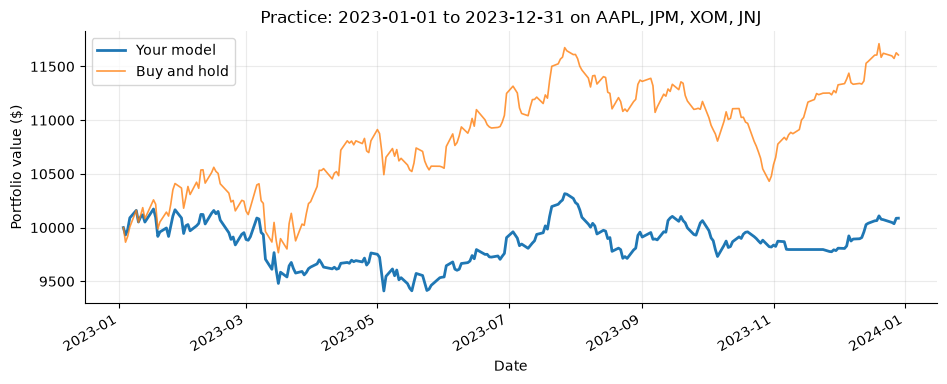

Saved as attempt #1. Sharpe: 0.14


0.13907215127560804

In [7]:
# Official contract check: valid float, deterministic output, unchanged input.
display(harness.smoke_check_predict(predict))

# Record one official practice attempt for the saved submission bundle.
practice_score(predict, note="Frozen selected model: " + str(report["selected_kind"]))


In [8]:
# Reproduce the unchanged organizer's full diagnostic matrix once.
# "Honest? yes" means only out of fit, not untouched during model design.
# 2020–2022 overlap fitting; 2023/2024 were reused as development checks.
RUN_ADDITIONAL_ROBUSTNESS = True
if RUN_ADDITIONAL_ROBUSTNESS:
    robustness_check(predict, note="Frozen model: reused 2023/2024 development diagnostics",
                     trained_through="2022-12-31")


Testing across years...


Testing across stock groups in 2024...


,Stocks,Your Sharpe,Buy & hold Sharpe,Your return,Honest?
Test,,,,,
2020,"JPM, XOM, PFE, CROX, M",-0.02,0.14,-2.4%,no: model saw this data
2021,"JPM, XOM, PFE, CROX, M",2.01,2.28,63.5%,no: model saw this data
2022,"JPM, XOM, PFE, CROX, M",1.06,0.28,17.5%,no: model saw this data
2023,"JPM, XOM, PFE, CROX, M",-0.28,-0.19,-4.6%,yes
2024,"JPM, XOM, PFE, CROX, M",0.97,0.67,12.2%,yes
Big tech (2024),"AAPL, MSFT, NVDA, META",1.88,1.99,65.5%,yes
Steady (2024),"JNJ, PG, KO, DUK",0.50,0.82,4.6%,yes
Struggling (2024),"INTC, F, M, HOG",-1.54,-0.93,-23.5%,yes
Volatile (2024),"PLUG, AAL, CROX, BA",0.98,-0.04,13.9%,yes


Honest tests: 6. Positive Sharpe in 4. Beat buy-and-hold in 2.
Typical (median) honest Sharpe: 0.73
Rows marked "no" overlap your training data. Their scores look better than they really are.
If your model is a hand-written rule that never trains on data, use:
   robustness_check(predict, trained_through=None)


## Step 6 · Save the submission

Fill in the real team members above, then rerun top to bottom. The next cell
calls the original organizer function unchanged. It checks serialization in a
fresh Python process and writes the required `.pkl` bundle.

Upload **both** the generated `.pkl` and this executed `.ipynb` to the organizer's
shared folder. In Colab, download the notebook with **File → Download → Download
.ipynb**. This notebook intentionally retains the end-of-2022 freeze so its
2023/2024 labels remain out of parameter fitting. Those years were reused for
development feedback, so they are not untouched tests. Do not silently retrain
through 2024 and reuse these scores as if they were unseen.


In [9]:
# Save with the exact organizer implementation preserved in setup.
save_submission(predict)


✅ Signal_Lab_submission.pkl saved and checked (0.1 MB).
   Test position on sample data: 0.0
   File location: /Users/camskimac/Documents/Codex/2026-10-30/meeting-10-30-ai-stock-trading/outputs/competition-submission/trading_competition/Signal_Lab_submission.pkl


PosixPath('/Users/camskimac/Documents/Codex/2026-10-30/meeting-10-30-ai-stock-trading/outputs/competition-submission/trading_competition/Signal_Lab_submission.pkl')

## Your 2-minute explanation · prepare every teammate

This outline is based on `report.json` generated from actual runs. Read the code
and edit the wording into your own explanation before presenting. Do not claim
to have personally tested ideas you have not reviewed.

**The first attempt did not beat the baseline.** The original `trend` selection had a 2023 practice Sharpe of **0.057**, versus **1.190** for buy and hold. It made **923 trades versus 8** for the baseline. These measured results, plus the recorded 2024 diagnostics, motivated adding the simple `starter_trend` and lower-turnover `defensive_trend` alternatives. This is development feedback: 2023/2024 are no longer untouched tests. The original attempt is preserved in `initial_attempt.json`.


| Judging topic | Evidence and explanation |
|---|---|
| **Model choice** | The frozen selection is **`starter_trend`**: the organizer's simple 20/100-day trend baseline. Explain its actual input features and position sizing using the embedded code. |
| **Iteration** | Recorded candidates: `starter_trend`, `defensive_trend`, `trend`, `extra_trees`, `ridge`. The recorded candidate `ridge` had a lower validation selection score (0.357); its mean validation Sharpe was 0.577. That comparison explains an idea that did not win selection; it does not establish that the model is universally bad. |
| **Validation** | Numerical candidate ranking uses 2019–2022 folds: Highest mean validation Sharpe minus 0.25 times its across-year standard deviation; ties alphabetically. Set before 2023 testing.. But 2023/2024 feedback influenced which candidate families were added. Those years are out of parameter training but reused development checks; only the organizer's hidden rounds are the unseen final test. |
| **Training data** | Reported stocks: AAL, AAPL, AMZN, BA, C, CAT, CROX, CVX, DIS, DUK, F, GIS, GOOGL, HOG, HON, INTC, JNJ, JPM, KO, M, META, MMM, MSFT, NEE, NKE, NVDA, PFE, PG, PLUG, T, UNH, VZ, WMT, XOM. Dates: **2015-01-01 through 2022-12-31**; 64328 eligible examples. The chosen practice freeze ends no later than 2022-12-31. Both future opens used as a training answer stay inside the training slice. |
| **Team understanding** | Everyone should explain `predict(history)`, one feature, why next-open timing prevents future-data leakage, and one weak result. Fill in the real team names before submitting. |

**A simple speaking order:** idea and model (25 seconds), actual alternatives
and what lost (25 seconds), dates and honest testing (30 seconds), measured
practice/check results and limitations (25 seconds), what each teammate can
explain (15 seconds). Use the displayed results; do not promise future profits.

### Quick questions to rehearse

- **What is a feature?** A numerical clue calculated from prior OHLCV history.
  Examples here include recent returns, a close relative to a rolling average,
  and recent volatility. No ticker name or future price is a feature.
- **What does training do?** It fits the selected return-model parameters from
  past examples. A trend-only winner uses a fixed rule instead; describe the
  actual selected kind, not an algorithm that lost validation.
- **Where could leakage happen?** A feature can accidentally see a future bar,
  a training target can cross a date boundary, or test results can influence
  model selection. These are separate checks. Predictions never retrain.
- **How do fees work?** The unchanged organizer harness charges 0.1% of traded
  notional on each transaction side, including final liquidation. More trading
  can erase a small predictive advantage.
- **What is a negative output?** A short target exposure. Zero means cash;
  positive means long. The submitted strategy's caps can be tighter than the
  allowed −1 to 1 range. Short exposure can lose when the stock rises.
- **Why Sharpe?** It compares average daily return with its variability and
  annualizes using 252 trading days. It is noisy, can change by stock and year,
  and is not a guarantee of profit.
- **What about little history?** The predictor returns `0.0` when there is
  insufficient valid history. It does not mutate the input or fetch data.

The rules permit 2015–2024 real data. This notebook intentionally freezes
training at 2022 to keep 2023/2024 evaluations out of its training data. No real
prices after 2024 are used for training, testing, or model choice. The organizer's
short-history smoke input uses synthetic dates; it is not market evidence.

The original robustness table's **“Honest? yes” means only that a row starts
after the recorded fitting cutoff**. It does not certify that the year was
untouched during model design. Here, 2023/2024 were reused for development;
2020–2022 diagnostic rows also overlap parameter training.


### Keep the evidence and rules clear

- Real data from 2025 onward must not be used for training, testing, or model
  selection. The secret rounds are outside the permitted development window.
- Do not treat this local score as a promise of performance on the secret stocks.
- Any teammate may be asked to explain the actual submitted model.
- No late submissions. Follow the organizer's upload instructions.
- The browser dashboard is a separate learning prototype, with different
  features, splitting, and long/cash rules; its exports are not this submission.
